### SciKit-Learn

In [ ]:
%pip install --upgrade scikit-learn

In [ ]:
import sklearn
print(sklearn.__version__)

1.9.1


In [ ]:
from sklearn.datasets import load_diabetes
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
x , y = load_diabetes(return_X_y=True)

In [ ]:
print(x.shape)
print(y.shape)

(442, 10)
(442,)


In [ ]:
x[1]

array([-0.00188202, -0.04464164, -0.05147406, -0.02632753, -0.00844872,
       -0.01916334,  0.07441156, -0.03949338, -0.06833155, -0.09220405])

In [ ]:
y[1]

np.float64(75.0)

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

In [ ]:
model = KNeighborsRegressor().fit(x,y)

In [ ]:
pred = model.predict(x)

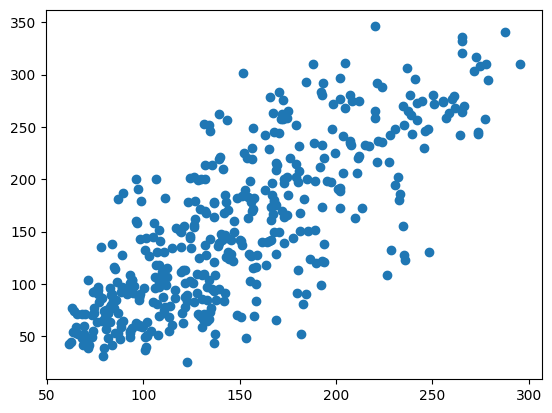

In [ ]:
plt.scatter(pred, y)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

In [ ]:
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=1))
])
pipe.get_params()

{'memory': None,
 'steps': [('scale', StandardScaler()),
  ('model', KNeighborsRegressor(n_neighbors=1))],
 'transform_input': None,
 'verbose': False,
 'scale': StandardScaler(),
 'model': KNeighborsRegressor(n_neighbors=1),
 'scale__copy': True,
 'scale__with_mean': True,
 'scale__with_std': True,
 'model__algorithm': 'auto',
 'model__leaf_size': 30,
 'model__metric': 'minkowski',
 'model__metric_params': None,
 'model__n_jobs': None,
 'model__n_neighbors': 1,
 'model__p': 2,
 'model__weights': 'uniform'}

In [ ]:
model = GridSearchCV(
    estimator = pipe,
    param_grid = {'model__n_neighbors': [1,2,3,4,5,6,7,8,9,10]},
    cv = 3
    )

In [ ]:
model.fit(x,y)
pd.DataFrame(model.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,0.007669,0.002008,0.008846,0.004561,1,{'model__n_neighbors': 1},0.105976,0.124092,-0.158523,0.023849,0.129168,10
1,0.010262,0.004555,0.008342,0.000464,2,{'model__n_neighbors': 2},0.268889,0.339379,0.264563,0.290944,0.034295,9
2,0.008585,0.003725,0.006928,0.002697,3,{'model__n_neighbors': 3},0.333057,0.382744,0.356899,0.357567,0.020290,8
3,0.004237,0.000161,0.005029,0.001002,4,{'model__n_neighbors': 4},0.342407,0.404701,0.409910,0.385673,0.030668,6
4,0.004147,0.000086,0.004296,0.000060,5,{'model__n_neighbors': 5},0.358865,0.377198,0.412549,0.382871,0.022280,7
5,0.009991,0.004430,0.013066,0.004519,6,{'model__n_neighbors': 6},0.372665,0.389923,0.436389,0.399659,0.026911,5
6,0.003918,0.000096,0.004520,0.000097,7,{'model__n_neighbors': 7},0.412584,0.393681,0.446147,0.417471,0.021696,4
7,0.004551,0.000930,0.004477,0.000100,8,{'model__n_neighbors': 8},0.414478,0.409779,0.485850,0.436702,0.034806,3
8,0.003989,0.000135,0.004600,0.000091,9,{'model__n_neighbors': 9},0.414191,0.412035,0.528462,0.451563,0.054383,2
9,0.003908,0.000148,0.004511,0.000258,10,{'model__n_neighbors': 10},0.408989,0.405303,0.544371,0.452888,0.064706,1


In [ ]:
# Accessing the best parameters and score from the Grid Search
print(f"Best Parameters: {model.best_params_}")
print(f"Best Cross-Validation R2 Score: {model.best_score_:.4f}")

Best Parameters: {'model__n_neighbors': 10}
Best Cross-Validation R2 Score: 0.4529


In [ ]:
pred = pipe.predict(x)

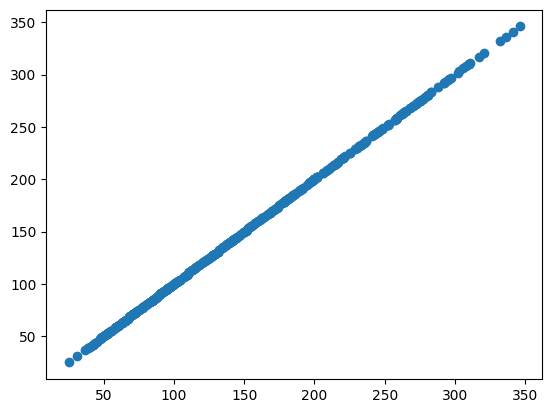

In [ ]:
plt.scatter(pred, y)

### Pre-Processing

In [ ]:
print(load_diabetes()['DESCR'])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee